In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Libraries imported successfully!") 

Libraries imported successfully!


In [3]:
df = pd.read_csv(r"C:\Users\DELL\OneDrive\ML\creditcard.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (284807, 31)


In [ ]:
print(df.head())
print("\nDataset Information:")
print(df.info())

   Time        V1        V2        V3        V4        V5        V6        V7  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255425  ... -0.225775 -0.638672  0.101288 -0.339846  0.167170   
2  0.247676 -1.514654  ...  0.247998  0.771679  0.909412 -0.689281 -0.327642   
3  0.377436 -1.387024  ... -0.108300  0.005274 -0.190321 -1.175575  0.647376   
4 -0.270533  0.817739  ... -0.009431  0.798278 -0.137458  0.141267 -0.206010   

        V26       V27       V28 

In [ ]:
print("Transaction Class Distribution:")
print(df["Class"].value_counts())
print("\nPercentage Distribution:")
print(df["Class"].value_counts(normalize=True) * 100)

Transaction Class Distribution:
Class
0    284315
1       492
Name: count, dtype: int64

Percentage Distribution:
Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64


In [ ]:
print("Missing Values:")
print(df.isnull().sum().sum())

Missing Values:
0


In [ ]:
X = df.drop("Class", axis=1)
y = df["Class"]
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (284807, 30)
Target shape: (284807,)


In [ ]:
scaler = StandardScaler()
X["Amount"] = scaler.fit_transform(X[["Amount"]])
X["Time"] = scaler.fit_transform(X[["Time"]])
print("Feature scaling completed!")

Feature scaling completed!


In [ ]:
# Separate features and target
X = df.drop("Class", axis=1)
y = df["Class"]

# Split the data first
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Scale using training data only
scaler = StandardScaler()

X_train = X_train.copy()
X_test = X_test.copy()

X_train[["Amount", "Time"]] = scaler.fit_transform(
    X_train[["Amount", "Time"]]
)

X_test[["Amount", "Time"]] = scaler.transform(
    X_test[["Amount", "Time"]]
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)


Training data: (227845, 30)
Testing data: (56962, 30)

Fraud cases in training: 394
Fraud cases in testing: 98


In [ ]:
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)
logistic_model.fit(X_train, y_train)
y_pred_lr = logistic_model.predict(X_test)
print("Logistic Regression Results")
print("Accuracy :", accuracy_score(y_test, y_pred_lr))
print("Precision:", precision_score(y_test, y_pred_lr))
print("Recall   :", recall_score(y_test, y_pred_lr))
print("F1 Score :", f1_score(y_test, y_pred_lr))

Logistic Regression Results
Accuracy : 0.9991573329588147
Precision: 0.8289473684210527
Recall   : 0.6428571428571429
F1 Score : 0.7241379310344828


In [ ]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)
print("Random Forest Results")
print("Accuracy :", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf))
print("Recall   :", recall_score(y_test, y_pred_rf))
print("F1 Score :", f1_score(y_test, y_pred_rf))

Random Forest Results
Accuracy : 0.9995962220427653
Precision: 0.9411764705882353
Recall   : 0.8163265306122449
F1 Score : 0.8743169398907104


In [ ]:
cm_lr = confusion_matrix(y_test, y_pred_lr)
cm_rf = confusion_matrix(y_test, y_pred_rf)
print("Logistic Regression Confusion Matrix:")
print(cm_lr)
print("\nRandom Forest Confusion Matrix:")
print(cm_rf)

Logistic Regression Confusion Matrix:
[[56851    13]
 [   35    63]]

Random Forest Confusion Matrix:
[[56859     5]
 [   18    80]]


In [ ]:
print("LOGISTIC REGRESSION")
print(classification_report(y_test, y_pred_lr))
print("\nRANDOM FOREST")
print(classification_report(y_test, y_pred_rf))

LOGISTIC REGRESSION
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.83      0.64      0.72        98

    accuracy                           1.00     56962
   macro avg       0.91      0.82      0.86     56962
weighted avg       1.00      1.00      1.00     56962


RANDOM FOREST
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.94      0.82      0.87        98

    accuracy                           1.00     56962
   macro avg       0.97      0.91      0.94     56962
weighted avg       1.00      1.00      1.00     56962



In [ ]:
comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_rf)
    ],
    "Precision": [
        precision_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_rf)
    ],
    "Recall": [
        recall_score(y_test, y_pred_lr),
        recall_score(y_test, y_pred_rf)
    ],
    "F1 Score": [
        f1_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_rf)
    ]
})

print(comparison)

                 Model  Accuracy  Precision    Recall  F1 Score
0  Logistic Regression  0.999157   0.828947  0.642857  0.724138
1        Random Forest  0.999596   0.941176  0.816327  0.874317


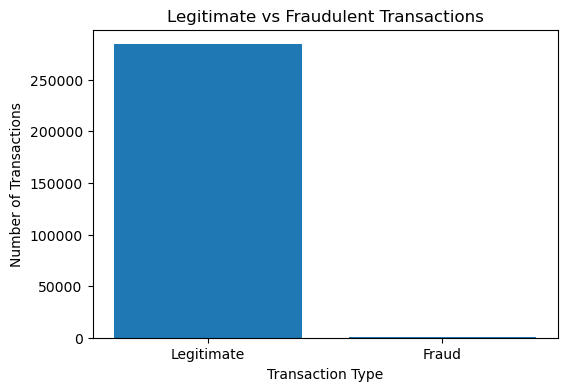

In [ ]:
class_counts = df["Class"].value_counts()
plt.figure(figsize=(6, 4))
plt.bar(["Legitimate", "Fraud"], class_counts.values)
plt.title("Legitimate vs Fraudulent Transactions")
plt.xlabel("Transaction Type")
plt.ylabel("Number of Transactions")
plt.show()

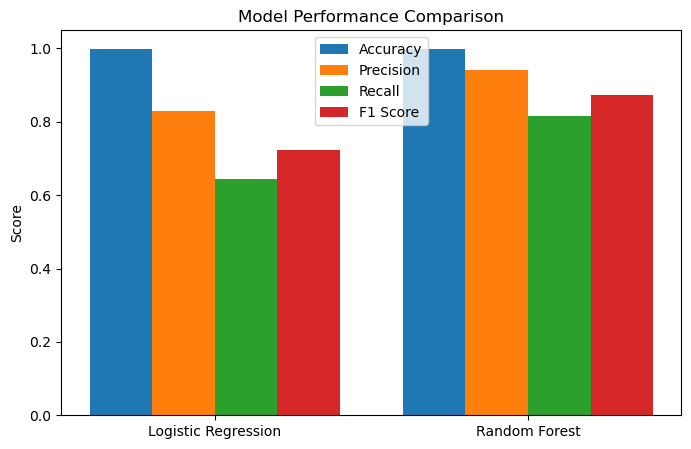

In [ ]:
plt.figure(figsize=(8, 5))
models = comparison["Model"]
accuracy = comparison["Accuracy"]
precision = comparison["Precision"]
recall = comparison["Recall"]
f1 = comparison["F1 Score"]
x = np.arange(len(models))
width = 0.2
plt.bar(x - 0.3, accuracy, width, label="Accuracy")
plt.bar(x - 0.1, precision, width, label="Precision")
plt.bar(x + 0.1, recall, width, label="Recall")
plt.bar(x + 0.3, f1, width, label="F1 Score")
plt.xticks(x, models)
plt.ylabel("Score")
plt.title("Model Performance Comparison")
plt.legend()
plt.show()

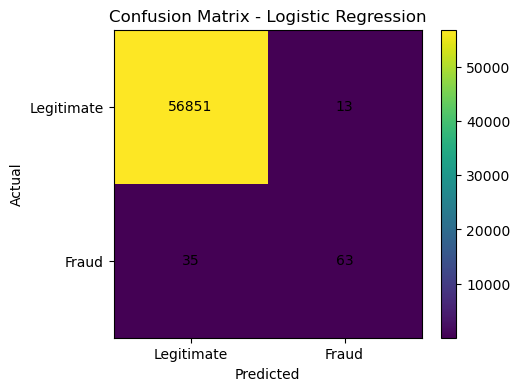

In [ ]:
# Confusion Matrix - Logistic Regression

plt.figure(figsize=(5, 4))
plt.imshow(cm_lr)
plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.colorbar()

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm_lr[i, j], ha="center", va="center")

plt.xticks([0, 1], ["Legitimate", "Fraud"])
plt.yticks([0, 1], ["Legitimate", "Fraud"])

plt.show()

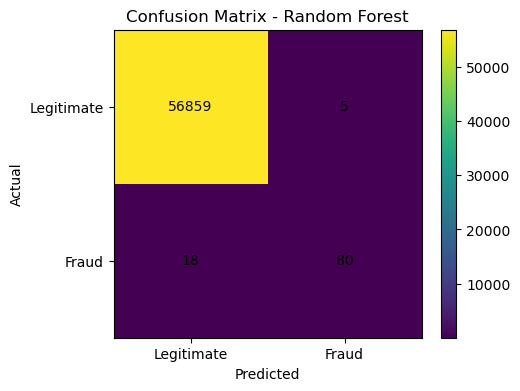

In [ ]:
# Confusion Matrix - Random Forest

plt.figure(figsize=(5, 4))
plt.imshow(cm_rf)
plt.title("Confusion Matrix - Random Forest")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.colorbar()

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm_rf[i, j], ha="center", va="center")

plt.xticks([0, 1], ["Legitimate", "Fraud"])
plt.yticks([0, 1], ["Legitimate", "Fraud"])

plt.show()

In [ ]:
best_model = comparison.loc[comparison["F1 Score"].idxmax(), "Model"]
print("CONCLUSION")
print("The Credit Card Fraud Detection system was developed using Logistic Regression and Random Forest.")
print("The dataset was preprocessed and divided into training and testing sets.")
print("Both models were evaluated using Accuracy, Precision, Recall and F1 Score.")
print("Due to the highly imbalanced nature of the dataset, Precision, Recall and F1 Score were considered important evaluation measures.")
print("Best performing model based on F1 Score:", best_model)

CONCLUSION
The Credit Card Fraud Detection system was developed using Logistic Regression and Random Forest.
The dataset was preprocessed and divided into training and testing sets.
Both models were evaluated using Accuracy, Precision, Recall and F1 Score.
Due to the highly imbalanced nature of the dataset, Precision, Recall and F1 Score were considered important evaluation measures.
Best performing model based on F1 Score: Random Forest
